In [44]:
import torch 
import os 
from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader,Dataset

In [45]:
class ImageDataset(Dataset):
    def __init__(self,image_dir,transform = None):
        self.image_dir= image_dir
        self.image_path = []
        self.labels = []
        self.class_name = {}
        self.transform = transform

        for label,class_dir in enumerate(os.listdir(image_dir)):
            self.class_name[label] = class_dir
            class_path = os.path.join(image_dir,class_dir)
            for img_name in os.listdir(class_path):
                self.image_path.append(os.path.join(class_path,img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_path)

    def  __getitem__(self, index):
        img_path = self.image_path[index]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[index]
        if self.transform:
            image = self.transform(image)
        return image, label 
    

In [46]:
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])]

    
)

In [47]:
train_image_dir = 'Classification_dataset_v3/images/train'
test_image_dir = 'Classification_dataset_v3/images/test'

train_image_dataset = ImageDataset(image_dir=train_image_dir, transform=transform)
test_image_dataset = ImageDataset(image_dir=test_image_dir, transform=transform)

In [48]:
train_image_loader = DataLoader(dataset=train_image_dataset, batch_size=32, shuffle=True)
test_image_loader = DataLoader(dataset=test_image_dataset, batch_size=32, shuffle=True)

In [31]:
for images,labels in train_image_loader:
  print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([3

In [49]:
import matplotlib.pyplot as plt
import numpy as np

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9764706..1.0].


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
Dog
(128, 128, 3)
1


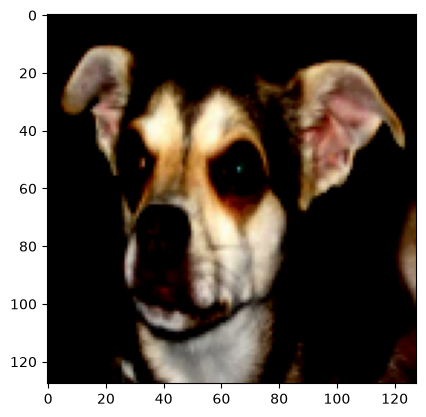

In [34]:
for images, labels in train_image_loader:
  print(images.shape, labels.shape)
  img = images[0].numpy()
  print(img.shape)
  label = labels[0].item()
  print(train_image_dataset.class_name[label])
  img = np.transpose(img, (1,2,0))
  print(img.shape)
  print(label)
  plt.imshow(img, vmin=0, vmax=255)
  break

# CNN architecture 

In [50]:
import torch.nn as nn 
import torch.optim as optim 

In [53]:
class CustomCnnModel(nn.Module):
    def __init__(self,input_dim,num_classes):
        super().__init__()
        self.input_dim = input_dim
        self.num_classes = num_classes

        self.conv_layers = nn.Sequential(
            #c1
            nn.Conv2d(3,32,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #c2
            nn.Conv2d(32,64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #c3
            nn.Conv2d(64,128,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            #c4
            nn.Conv2d(128,256,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

        )

        self.to_linear = None
        self._get_conv_output(self.input_dim)

        self.fc_layer = nn.Sequential(
            nn.Linear(self.to_linear,512),
            nn.ReLU(),
            nn.Linear(512,128),
            nn.ReLU(),
            nn.Linear(128,self.num_classes)

        )

    def _get_conv_output(self,input_dim=128):
        with torch.no_grad():
            dummy_input = torch.zeros(1,3,input_dim,input_dim)
            output = self.conv_layers(dummy_input)
            self.to_linear = output.view(1,-1).size(1)

    def forward(self,x):
        x = self.conv_layers(x)
        x = x.view(x.size(0),-1)
        x = self.fc_layer(x)

        return x
    

In [54]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = CustomCnnModel(input_dim=128,num_classes=3).to(device)

In [56]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.01)


In [64]:
# training Loop
epoch = 100
for e in range(epoch):
    model.train()
    running_loss = 0.0
    for images ,labels in train_image_loader:
        images,labels =images.to(device),labels.to(device)
        optimizer.zero_grad()
        output = model(images)
        loss =criterion(output,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {e+1}/{epoch}, Loss : {running_loss/len(train_image_loader)}")
          

Epoch1/100, Loss : 0.6369180196209958
Epoch2/100, Loss : 0.6290642546980004
Epoch3/100, Loss : 0.6159948813287836
Epoch4/100, Loss : 0.5789819105675346
Epoch5/100, Loss : 0.5697289077859176
Epoch6/100, Loss : 0.5614082007031692
Epoch7/100, Loss : 0.543532218117463
Epoch8/100, Loss : 0.5102161184737557
Epoch9/100, Loss : 0.5348676358398639
Epoch10/100, Loss : 0.5648395676361887
Epoch11/100, Loss : 0.5060815205699519
Epoch12/100, Loss : 0.4843643652765374
Epoch13/100, Loss : 0.5370539643262562
Epoch14/100, Loss : 0.495842498854587
Epoch15/100, Loss : 0.5131000885837956
Epoch16/100, Loss : 0.4613160418836694
Epoch17/100, Loss : 0.4544054028234984
Epoch18/100, Loss : 0.4233912734608901
Epoch19/100, Loss : 0.47432376554137784
Epoch20/100, Loss : 0.43195035190958725
Epoch21/100, Loss : 0.4113284950193606
Epoch22/100, Loss : 0.3849029297891416
Epoch23/100, Loss : 0.48892038323377307
Epoch24/100, Loss : 0.38877362044234026
Epoch25/100, Loss : 0.3520027715908854
Epoch26/100, Loss : 0.3684326054

In [65]:
torch.save(model.state_dict(),"cnn_model.pth")


In [68]:
model.eval()
correct = 0
total = 0 

with torch.no_grad():
    for images,labels in test_image_loader:
        images,labels = images.to(device),labels.to(device)
        output = model(images)
        _, predicted = torch.max(output,1)
        total += labels.size(0)
        correct +=(predicted == labels).sum().item()

print(f"Test accuracy is {100*correct/total: .2f}%")

Test accuracy is  81.00%


In [69]:
import cv2

In [74]:
class ImageClassifier:
    def __init__(self,model_path,class_names):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        self.model = CustomCnnModel(input_dim=128,num_classes=3).to(device)
        self.model.load_state_dict(torch.load(model_path,map_location=device))
        self.model.eval()
        self.class_name = class_names
        self.transform = transforms.Compose([
                transforms.Resize((128,128)),
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])])

    def predict(self,image_path):
        image = Image.open(image_path).convert("RGB")
        input_tensor = self.transform(image).unsqueeze(0).to(device)
        with torch.no_grad():
            output = self.model(input_tensor)
            _, predicted = torch.max(output,1)
            label = self.class_name[predicted.item()]

            img = cv2.imread(image_path)
            cv2.putText(img,label,(10,30),cv2.FONT_HERSHEY_COMPLEX,1,(255,0,0),2)
            cv2.imwrite("output_Image.jpg",img)
            return label
        



In [75]:
classifier = ImageClassifier("./cnn_model.pth",train_image_dataset.class_name)


In [76]:
label = classifier.predict("./Classification_dataset_v3/images/test/dog/dog_1000.jpg")
print(label)

Dog
